[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/FiapGrupoEntregas/Cap-1---O-despertar-da-Rede-Neural/blob/main/src/JonattasFelipe_rm572692_pbl_fase6.ipynb)

# FarmTech Solutions – Fase 6: Visão Computacional com YOLO

**Grupo:**
- Jonattas Felipe – RM572692
- Natanael Filho – RM572474
- Pedro Henrique – RM571394
- Andrews Oliveira – RM572311

Notebook organizado em:
0. Ambiente de execução (Google Colab ou máquina local com uv)
1. Preparação do dataset (Open Images V7)
2. Rotulação no Make Sense
3. Entrega 1: YOLOv5 customizado (30 e 60 épocas)
4. Entrega 2: YOLO padrão e CNN do zero, com comparação final
5. Conclusões

**Objetos escolhidos:** Trator (A) e Vaca/gado (B), alinhados ao contexto agro da FarmTech.

## 0. Ambiente de execução

O mesmo notebook roda em dois ambientes:

| | Google Colab | Máquina local |
|---|---|---|
| Como abrir | botão *Open in Colab* (com GPU: *Ambiente de execução > Alterar tipo*) | `uv sync --extra dataset` e depois `uv run jupyter lab` |
| Dependências | instaladas pelo próprio notebook com `pip` | travadas no `uv.lock`; o notebook não instala nada |
| Onde ficam os dados | Google Drive, em `MyDrive/FarmTech_Fase6` | pasta do repositório (`dataset/`, `assets/`, `models/`) |
| Arquivos temporários | `/content` | `.trabalho/` (ignorada pelo git) |

In [3]:
# Detecta onde o notebook está rodando e define as pastas usadas em todo o projeto
import os, sys, io, random, shutil, subprocess, time, zipfile, re
from pathlib import Path

EM_COLAB = 'google.colab' in sys.modules                         # True no Google Colab, False na máquina local (uv)
REPO_URL = 'https://github.com/FiapGrupoEntregas/Cap-1---O-despertar-da-Rede-Neural.git'

if EM_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')                                 # conecta ao Google Drive
    BASE = Path('/content/drive/MyDrive/FarmTech_Fase6')         # pasta do projeto no Drive
    REPO = Path('/content/repo')                                  # cópia do repositório do GitHub
    if not REPO.exists():
        subprocess.run(['git', 'clone', '-q', REPO_URL, str(REPO)], check=True)
    TRABALHO = Path('/content')                                   # disco local do Colab: bem mais rápido que o Drive
else:
    REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'uv.lock').exists())   # raiz do repositório
    BASE = REPO                                                   # sem Drive: dados e resultados ficam no repositório
    TRABALHO = REPO / '.trabalho'                                 # YOLOv5, execuções e logs (ignorada pelo git)

DATASET = BASE / 'dataset'                                        # imagens e rótulos no formato YOLO
ASSETS = BASE / 'assets'                                          # figuras usadas no README
MODELOS = BASE / 'models'                                         # best.pt escolhido (usado no "Ir Além")
LOGS = TRABALHO / 'logs'                                          # saída completa dos scripts do YOLOv5
for pasta in (BASE, TRABALHO, ASSETS, MODELOS, LOGS):
    pasta.mkdir(parents=True, exist_ok=True)

if not EM_COLAB:
    os.environ['YOLO_CONFIG_DIR'] = str(TRABALHO / 'ultralytics')   # configurações do Ultralytics dentro de .trabalho/
    from ultralytics import settings
    settings.update({'weights_dir': str(TRABALHO / 'pesos'), 'runs_dir': str(TRABALHO / 'runs_ultralytics'), 'sync': False})

# O repositório já traz o dataset rotulado? Se sim, o download e a pré-rotulação são pulados
DATASET_PRONTO = any((REPO / 'dataset' / 'labels' / 'train').glob('*.txt'))
if EM_COLAB and not DATASET_PRONTO:
    !pip install -q ultralytics git+https://github.com/ultralytics/CLIP.git   # YOLO-World, usado na pré-rotulação

print('Ambiente:', 'Google Colab' if EM_COLAB else 'local (uv)')
print('Dataset rotulado no repositório:', 'sim' if DATASET_PRONTO else 'não')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Ambiente: Google Colab
Dataset rotulado no repositório: não


## 1. Preparação do dataset

As imagens vêm do dataset público **Open Images V7** (Google) e são baixadas direto dos arquivos oficiais, sem conta, API ou banco de dados.

Passos:
1. Ler os rótulos verificados por humanos dos splits `validation` e `test` do Open Images, que são bem menores que o `train`. Separar as fotos com **trator** e com **vaca/gado** e descartar as que têm as duas classes.
2. Manter só fotos com **um único objeto da classe**, o que facilita a rotulação e evita ambiguidade:
   - **vaca:** o Open Images tem caixas para `Cattle`. Ficam as fotos com exatamente 1 caixa de bovino, que não seja de grupo (`IsGroupOf`) nem desenho (`IsDepiction`).
   - **trator:** o Open Images **não tem caixas** para `Tractor`, só o rótulo de imagem. As candidatas passam pelo **YOLO-World**, um YOLO de vocabulário aberto que detecta classes descritas por texto, e ficam as fotos com exatamente 1 trator detectado.
3. Sortear 40 fotos por classe (semente 42) e dividir em **32 treino / 4 validação / 4 teste**, reduzindo o lado maior para 640 px.
4. Salvar as caixas em formato YOLO como **pré-rotulação**, revisada no Make Sense na etapa 2.

In [4]:
import pandas as pd, numpy as np
import requests
from PIL import Image

CLASSES = {'trator': '/m/013xlm', 'vaca': '/m/01xq0k1'}           # nome no projeto -> ID no Open Images (ids YOLO 0 e 1)
N_POR_CLASSE = 40
SPLITS = {'train': 32, 'val': 4, 'test': 4}

if DATASET_PRONTO and DATASET != REPO / 'dataset':                 # no Colab: copia o dataset do GitHub para o Drive
    shutil.copytree(REPO / 'dataset', DATASET, dirs_exist_ok=True)
for s in SPLITS:                                                  # estrutura de pastas esperada pelo YOLOv5
    (DATASET / 'images' / s).mkdir(parents=True, exist_ok=True)
    (DATASET / 'labels' / s).mkdir(parents=True, exist_ok=True)
print('Dataset encontrado no repositório: download e pré-rotulação serão pulados.' if DATASET_PRONTO
      else 'Dataset não encontrado: montando a partir do Open Images V7.')

Dataset não encontrado: montando a partir do Open Images V7.


In [5]:
OI = 'https://storage.googleapis.com/openimages'                   # arquivos oficiais de anotação do Open Images
S3 = 'https://open-images-dataset.s3.amazonaws.com'                # imagens públicas do Open Images
PASTA_OI = {'val': 'validation', 'test': 'test'}                  # splits do Open Images usados como fonte
BOI = '/m/0cnyhnx'                                                 # classe 'Bull': outro bovino, não pode aparecer junto

if not DATASET_PRONTO:
    # Rótulos de imagem verificados por humanos: Confidence = 1 significa "a classe aparece na foto"
    rot = pd.concat([pd.read_csv(f'{OI}/v7/oidv7-{s}-annotations-human-imagelabels.csv').assign(split=s) for s in PASTA_OI])
    rot = rot[(rot.Confidence == 1) & rot.LabelName.isin(CLASSES.values())]
    split_oi = dict(zip(rot.ImageID, rot.split))                    # split de origem de cada foto (define a URL)
    fotos = {nome: set(rot.ImageID[rot.LabelName == id_oi]) for nome, id_oi in CLASSES.items()}
    ambas = fotos['trator'] & fotos['vaca']                          # fotos com as duas classes ficam de fora

    # Caixas desenhadas por humanos (só existem para classes "boxable": Cattle tem, Tractor não)
    cols = ['ImageID', 'LabelName', 'XMin', 'XMax', 'YMin', 'YMax', 'IsGroupOf', 'IsDepiction']
    cx = pd.concat([pd.read_csv(f'{OI}/v5/{PASTA_OI[s]}-annotations-bbox.csv', usecols=cols) for s in PASTA_OI])
    bovinos = cx[cx.LabelName.isin([CLASSES['vaca'], BOI])]
    n_bov = bovinos.groupby('ImageID').size()                       # quantos bovinos têm caixa em cada foto

    # Vaca: exatamente 1 bovino na foto, da classe Cattle, sem ser caixa de grupo nem desenho
    v = bovinos[bovinos.ImageID.isin(n_bov.index[n_bov == 1]) & (bovinos.LabelName == CLASSES['vaca'])
                & (bovinos.IsGroupOf == 0) & (bovinos.IsDepiction == 0)
                & bovinos.ImageID.isin(fotos['vaca'] - ambas)].sort_values('ImageID')
    candidatas_vaca = [(r.ImageID, ((r.XMin + r.XMax) / 2, (r.YMin + r.YMax) / 2, r.XMax - r.XMin, r.YMax - r.YMin))
                       for r in v.itertuples()]                      # caixa YOLO: x_centro, y_centro, largura, altura

    # Trator: foto verificada com trator e sem gado; a caixa vem do YOLO-World na próxima célula
    candidatas_trator = sorted(fotos['trator'] - ambas - set(bovinos.ImageID))
    print(f'Candidatas: {len(candidatas_trator)} fotos com trator | {len(candidatas_vaca)} fotos com 1 vaca')

Candidatas: 207 fotos com trator | 121 fotos com 1 vaca


In [6]:
def baixar(image_id, destino, lado_max=640):
    """Baixa a foto do Open Images, reduz o lado maior para 640 px (mantendo a proporção) e salva em JPG."""
    r = requests.get(f'{S3}/{PASTA_OI[split_oi[image_id]]}/{image_id}.jpg', timeout=60)
    r.raise_for_status()
    img = Image.open(io.BytesIO(r.content)).convert('RGB')
    img.thumbnail((lado_max, lado_max))
    img.save(destino, 'JPEG', quality=92)

if not DATASET_PRONTO:
    from ultralytics import YOLOWorld
    detector = YOLOWorld(str(TRABALHO / 'yolov8s-worldv2.pt'))      # YOLO de vocabulário aberto (pesos baixados na 1ª vez)
    detector.set_classes(['tractor'])                                # descreve por texto o que procurar

    pasta_cand = TRABALHO / 'candidatas_trator'
    pasta_cand.mkdir(exist_ok=True)
    tratores = []
    for image_id in candidatas_trator:
        destino = pasta_cand / f'{image_id}.jpg'
        if not destino.exists():
            try:
                baixar(image_id, destino)
            except requests.RequestException:
                continue                                             # foto indisponível no servidor: pula
        caixas = detector.predict(destino, conf=0.25, verbose=False)[0].boxes
        if len(caixas) == 1:                                         # exatamente 1 trator detectado
            tratores.append((image_id, tuple(caixas.xywhn[0].tolist()), float(caixas.conf[0])))
    print(f'trator: {len(tratores)} de {len(candidatas_trator)} fotos com exatamente 1 trator detectado')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


100%|████████████████████████████████████████| 338M/338M [00:01<00:00, 282MiB/s]


trator: 104 de 207 fotos com exatamente 1 trator detectado


In [7]:
# Fotos reprovadas na conferência visual das caixas (desenho, brinquedo, caixa errada ou foto confusa)
EXCLUIR = set()

if not DATASET_PRONTO:
    fontes = {'trator': [(i, caixa, f'YOLO-World (conf {c:.2f})') for i, caixa, c in tratores],
              'vaca': [(i, caixa, 'Open Images (caixa desenhada por humano)') for i, caixa in candidatas_vaca]}
    ordem_split = [s for s, qtd in SPLITS.items() for _ in range(qtd)]   # 32 x train, 4 x val, 4 x test
    sorteio = random.Random(42)                                     # sorteio reprodutível
    origem = []
    for id_classe, (nome, itens) in enumerate(fontes.items()):
        itens = [it for it in itens if it[0] not in EXCLUIR]
        sorteio.shuffle(itens)
        n = 0
        for image_id, (xc, yc, w, h), fonte in itens:
            if n == N_POR_CLASSE:
                break
            split, arquivo = ordem_split[n], f'{nome}_{n + 1:02d}'
            imagem = DATASET / 'images' / split / f'{arquivo}.jpg'
            try:
                if nome == 'trator':                                 # já baixada e reduzida na célula anterior
                    shutil.copy(TRABALHO / 'candidatas_trator' / f'{image_id}.jpg', imagem)
                else:
                    baixar(image_id, imagem)
            except requests.RequestException:
                continue                                             # foto indisponível: passa para a próxima
            # Pré-rótulo YOLO: classe x_centro y_centro largura altura (relativos, então valem para a foto reduzida)
            (DATASET / 'labels' / split / f'{arquivo}.txt').write_text(f'{id_classe} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}\n')
            origem.append({'arquivo': f'{split}/{arquivo}.jpg', 'image_id_open_images': image_id,
                           'split_open_images': PASTA_OI[split_oi[image_id]], 'pre_rotulo': fonte})
            n += 1
        assert n == N_POR_CLASSE, f'Só {n} fotos de {nome}: amplie as fontes de candidatas'
    pd.DataFrame(origem).to_csv(DATASET / 'origem.csv', index=False)  # rastreabilidade: de onde veio cada foto

for s in SPLITS:
    print(s, len(list((DATASET / 'images' / s).glob('*.jpg'))), 'imagens')

train 64 imagens
val 8 imagens
test 8 imagens


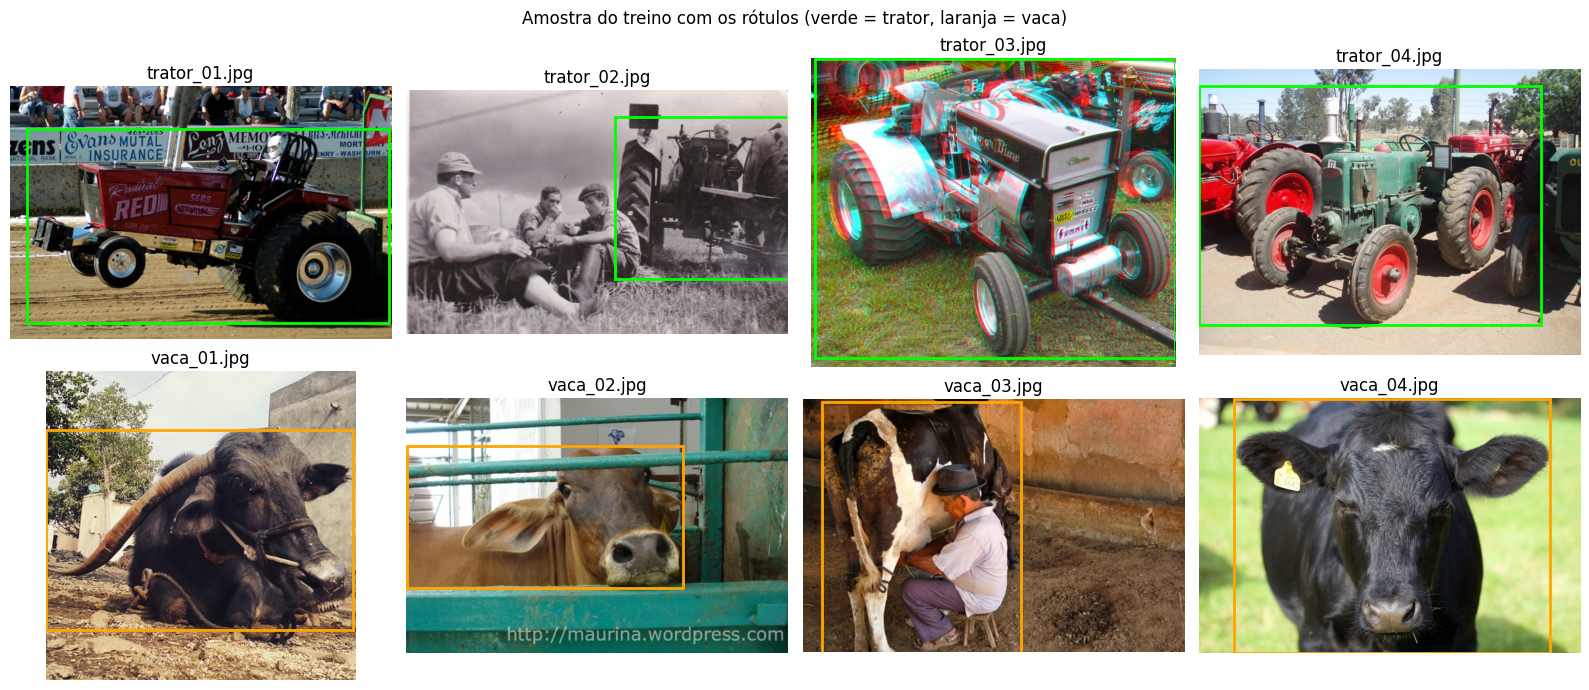

In [8]:
# Confere visualmente uma amostra de cada classe, com a caixa do rótulo desenhada por cima
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def desenhar_rotulo(ax, imagem):
    """Mostra a imagem e desenha a caixa do rótulo YOLO (.txt de mesmo nome)."""
    img = Image.open(imagem)
    W, H = img.size
    ax.imshow(img); ax.set_title(imagem.name); ax.axis('off')
    for linha in (DATASET / 'labels' / imagem.parent.name / f'{imagem.stem}.txt').read_text().splitlines():
        c, xc, yc, w, h = map(float, linha.split())
        ax.add_patch(patches.Rectangle(((xc - w / 2) * W, (yc - h / 2) * H), w * W, h * H,
                                       fill=False, lw=2, color='lime' if c == 0 else 'orange'))

fig, eixos = plt.subplots(2, 4, figsize=(16, 7))
for linha, nome in enumerate(CLASSES):
    for ax, f in zip(eixos[linha], sorted((DATASET / 'images' / 'train').glob(f'{nome}_*.jpg'))[:4]):
        desenhar_rotulo(ax, f)
fig.suptitle('Amostra do treino com os rótulos (verde = trator, laranja = vaca)')
plt.tight_layout(); plt.show()

In [9]:
# Pacotes para o Make Sense: imagens de cada split + rótulos YOLO com a lista de classes (labels.txt)
PASTA_MS = (BASE if EM_COLAB else TRABALHO) / 'para_makesense'
PASTA_MS.mkdir(exist_ok=True)
for s in SPLITS:
    with zipfile.ZipFile(PASTA_MS / f'{s}_imagens.zip', 'w') as z:
        for f in sorted((DATASET / 'images' / s).glob('*.jpg')):
            z.write(f, f.name)
    with zipfile.ZipFile(PASTA_MS / f'{s}_rotulos.zip', 'w') as z:
        z.writestr('labels.txt', '\n'.join(CLASSES) + '\n')        # ordem das classes: trator = 0, vaca = 1
        for f in sorted((DATASET / 'labels' / s).glob('*.txt')):
            z.write(f, f.name)
print('Pacotes para o Make Sense em:', PASTA_MS if EM_COLAB else PASTA_MS.relative_to(REPO))

Pacotes para o Make Sense em: /content/drive/MyDrive/FarmTech_Fase6/para_makesense


**Fonte das imagens:** Open Images V7 (Google), fotos com licença CC BY 2.0 e anotações com licença CC BY 4.0. O ID original de cada foto e a origem do pré-rótulo estão em `dataset/origem.csv`. As imagens são usadas apenas para fins acadêmicos.

## 2. Rotulação no Make Sense

A pré-rotulação acelera o trabalho, mas **toda caixa é revisada à mão no Make Sense**:

1. Acesse https://www.makesense.ai, clique em *Get Started* e carregue as imagens de um split (descompacte `train_imagens.zip`).
2. Escolha *Object Detection*. Em *Actions > Import Annotations*, escolha **YOLO** e envie os `.txt` e o `labels.txt` de `train_rotulos.zip`. As caixas aparecem com as labels `trator` (id 0) e `vaca` (id 1).
3. Revise imagem por imagem: ajuste as caixas mal posicionadas, apague as erradas e desenhe as que faltarem.
4. Em *Actions > Export Annotations*, escolha **A .zip package containing files in YOLO format**.
5. Salve o ZIP exportado como `labels_zips/train.zip`: no Drive, quando estiver no Colab, ou na raiz do repositório, quando estiver local. Repita para `val` e `test`.

A célula abaixo usa os ZIPs exportados do Make Sense quando eles existem (eles substituem a pré-rotulação) e confere se toda imagem tem rótulo.

In [10]:
# Se existirem os ZIPs exportados do Make Sense, eles substituem a pré-rotulação
for s in SPLITS:
    zip_path = BASE / 'labels_zips' / f'{s}.zip'
    if zip_path.exists():
        with zipfile.ZipFile(zip_path) as z:
            for membro in z.namelist():
                if membro.endswith('.txt') and Path(membro).name != 'labels.txt':   # ignora a lista de classes
                    (DATASET / 'labels' / s / Path(membro).name).write_bytes(z.read(membro))
    print(f'{s}: rótulos', f'do Make Sense ({zip_path.name})' if zip_path.exists() else 'do dataset (pré-rotulação)')

# Confere: toda imagem precisa ter um .txt de mesmo nome, com classe 0 ou 1
for s in SPLITS:
    imgs = sorted((DATASET / 'images' / s).glob('*.jpg'))
    sem_label = [i.name for i in imgs if not (DATASET / 'labels' / s / (i.stem + '.txt')).exists()]
    classes_usadas = set()
    for t in (DATASET / 'labels' / s).glob('*.txt'):
        for linha in t.read_text().splitlines():
            if linha.strip():
                classes_usadas.add(int(linha.split()[0]))
    print(f'{s}: {len(imgs)} imagens | sem rótulo: {sem_label} | classes: {classes_usadas}')

train: rótulos do dataset (pré-rotulação)
val: rótulos do dataset (pré-rotulação)
test: rótulos do dataset (pré-rotulação)
train: 64 imagens | sem rótulo: [] | classes: {0, 1}
val: 8 imagens | sem rótulo: [] | classes: {0, 1}
test: 8 imagens | sem rótulo: [] | classes: {0, 1}


## 3. Entrega 1 – YOLOv5 customizado

**Passo a passo:**
1. **Preparo:** criar o `data.yaml` com as pastas do dataset e baixar o YOLOv5 em um commit fixo. No Colab, o dataset é copiado do Drive para o disco local, porque o treino lendo do Drive é bem mais lento.
2. **Treino:** *fine-tuning* do `yolov5s.pt` (pré-treinado no COCO) com nossas duas classes, em duas simulações: **30 e 60 épocas**.
3. **Validação:** curvas de erro (loss), precisão, recall e mAP calculadas pelo YOLO a cada época sobre a pasta `val`.
4. **Teste:** avaliação do `best.pt` nas imagens da pasta `test`, nunca vistas no treino, e visualização das detecções.

O log completo de cada script do YOLOv5 fica em `logs/`; o notebook mostra só o resumo final.

In [11]:
# No Colab, copia o dataset do Drive para o disco local (treino mais rápido); localmente usa a pasta do repositório
LOCAL = TRABALHO / 'dataset_local' if EM_COLAB else DATASET
if EM_COLAB:
    shutil.copytree(DATASET, LOCAL, dirs_exist_ok=True)

# Arquivo de configuração do dataset para o YOLOv5
DATA_YAML = TRABALHO / 'data.yaml'
DATA_YAML.write_text('\n'.join([f'path: {LOCAL.as_posix()}', 'train: images/train', 'val: images/val',
                                'test: images/test', 'nc: 2', "names: ['trator', 'vaca']", '']))
if EM_COLAB:
    shutil.copy(DATA_YAML, BASE / 'data.yaml')                      # guarda uma cópia no Drive

# Baixa o YOLOv5 em um commit fixo (reprodutibilidade); no Colab, instala as dependências dele
YOLO_DIR = TRABALHO / 'yolov5'
YOLO_COMMIT = 'f9578796b8a64889aa9e66dc06914d19f40d338e'
if not YOLO_DIR.exists():
    subprocess.run(['git', 'clone', '-q', 'https://github.com/ultralytics/yolov5', str(YOLO_DIR)], check=True)
subprocess.run(['git', '-C', str(YOLO_DIR), 'checkout', '-q', YOLO_COMMIT], check=True)
if EM_COLAB:
    !pip install -q -r {YOLO_DIR}/requirements.txt

ANSI = re.compile(r'\x1b\[[0-9;]*m')                                # códigos de cor do terminal

def rodar(script, *args, log):
    """Roda um script do YOLOv5 na pasta dele, grava o log completo em logs/ e devolve as linhas da saída."""
    arquivo_log = LOGS / f'{log}.log'
    with open(arquivo_log, 'w') as saida:                           # o log é gravado durante a execução
        proc = subprocess.run([sys.executable, script, *map(str, args)], cwd=YOLO_DIR,
                              stdout=saida, stderr=subprocess.STDOUT, env={**os.environ, 'PYTHONUNBUFFERED': '1'})
    # Barras de progresso reescrevem a linha com '\r': fica só o estado final de cada uma
    linhas = [ANSI.sub('', l.split('\r')[-1]) for l in arquivo_log.read_text().splitlines()]
    if proc.returncode != 0:
        print('\n'.join(linhas[-30:]))
        raise RuntimeError(f'{script} falhou; log completo em logs/{log}.log')
    return linhas

def resumo_treino(linhas):
    """Trecho final do treino: tempo total e métricas do best.pt na validação."""
    inicio = next((i for i, l in enumerate(linhas) if 'epochs completed' in l), len(linhas) - 12)
    return '\n'.join(l for l in linhas[inicio:] if l.strip())

In [12]:
# Versões do ambiente (registradas automaticamente para reprodutibilidade)
import platform, torch
from importlib.metadata import version, PackageNotFoundError

def nome_cpu():
    """Modelo do processador (Linux), usado para contextualizar os tempos medidos."""
    try:
        return next(l.split(':', 1)[1].strip() for l in open('/proc/cpuinfo') if l.startswith('model name'))
    except (OSError, StopIteration):
        return platform.processor() or platform.machine()

print('Python:', platform.python_version(), '|', 'Google Colab' if EM_COLAB else 'local (uv)')
for pacote in ['torch', 'torchvision', 'tensorflow', 'ultralytics', 'opencv-python', 'pandas', 'numpy',
               'matplotlib', 'scikit-learn', 'pillow']:
    try:
        print(f'{pacote}: {version(pacote)}')
    except PackageNotFoundError:
        print(f'{pacote}: não instalado')
commit = subprocess.run(['git', '-C', str(YOLO_DIR), 'rev-parse', '--short', 'HEAD'], capture_output=True, text=True).stdout.strip()
print('YOLOv5 (ultralytics/yolov5) commit:', commit, '| pesos iniciais: yolov5s.pt (COCO)')
DISPOSITIVO = f'GPU {torch.cuda.get_device_name(0)}' if torch.cuda.is_available() else f'CPU {nome_cpu()}'
print('Dispositivo:', DISPOSITIVO)

Python: 3.13.15 | Google Colab
torch: 2.11.0+cu130
torchvision: 0.26.0+cu130
tensorflow: 2.21.0
ultralytics: 8.4.177
opencv-python: 5.0.0.93
pandas: 2.2.3
numpy: 2.1.3
matplotlib: 3.10.0
scikit-learn: 1.6.1
pillow: 11.3.0
YOLOv5 (ultralytics/yolov5) commit: f9578796 | pesos iniciais: yolov5s.pt (COCO)
Dispositivo: GPU Tesla T4


In [13]:
# Simulação 1: 30 épocas
IMG, BATCH = 640, 8                                                # tamanho da imagem e do lote nas duas simulações
t0 = time.time()
saida = rodar('train.py', '--img', IMG, '--batch', BATCH, '--epochs', 30, '--data', DATA_YAML, '--weights', 'yolov5s.pt',
              '--name', 'exp_30ep', '--exist-ok', '--workers', 2, '--cache', 'ram', log='treino_30ep')
tempo_treino_30 = time.time() - t0
print(resumo_treino(saida))
print(f'\nTempo de treino (30 épocas): {tempo_treino_30/60:.1f} min')

30 epochs completed in 0.014 hours.
Optimizer stripped from runs/train/exp_30ep/weights/last.pt, 14.4MB
Optimizer stripped from runs/train/exp_30ep/weights/best.pt, 14.4MB
Validating runs/train/exp_30ep/weights/best.pt...
Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 1/1 10.4it/s 0.1s
                   all          8          8      0.971          1      0.995      0.793
                trator          8          4      0.978          1      0.995      0.796
                  vaca          8          4      0.963          1      0.995      0.789
Results saved to runs/train/exp_30ep

Tempo de treino (30 épocas): 1.5 min


In [14]:
# Simulação 2: 60 épocas (mesmos parâmetros, só muda o número de épocas)
t0 = time.time()
saida = rodar('train.py', '--img', IMG, '--batch', BATCH, '--epochs', 60, '--data', DATA_YAML, '--weights', 'yolov5s.pt',
              '--name', 'exp_60ep', '--exist-ok', '--workers', 2, '--cache', 'ram', log='treino_60ep')
tempo_treino_60 = time.time() - t0
print(resumo_treino(saida))
print(f'\nTempo de treino (60 épocas): {tempo_treino_60/60:.1f} min')

60 epochs completed in 0.029 hours.
Optimizer stripped from runs/train/exp_60ep/weights/last.pt, 14.4MB
Optimizer stripped from runs/train/exp_60ep/weights/best.pt, 14.4MB
Validating runs/train/exp_60ep/weights/best.pt...
Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 1/1 10.8it/s 0.1s
                   all          8          8      0.983          1      0.995      0.785
                trator          8          4      0.999          1      0.995      0.766
                  vaca          8          4      0.967          1      0.995      0.805
Results saved to runs/train/exp_60ep

Tempo de treino (60 épocas): 2.3 min


### 3.1 Validação: curvas de treino

O YOLO registra em `results.csv` as métricas de cada época. Abaixo comparo as duas simulações.

,Simulação,Precisão,Recall,mAP@0.5,mAP@0.5:0.95,Loss val (box)
0,30 épocas,0.970,1.0,0.995,0.793,0.008
1,60 épocas,0.984,1.0,0.995,0.785,0.007


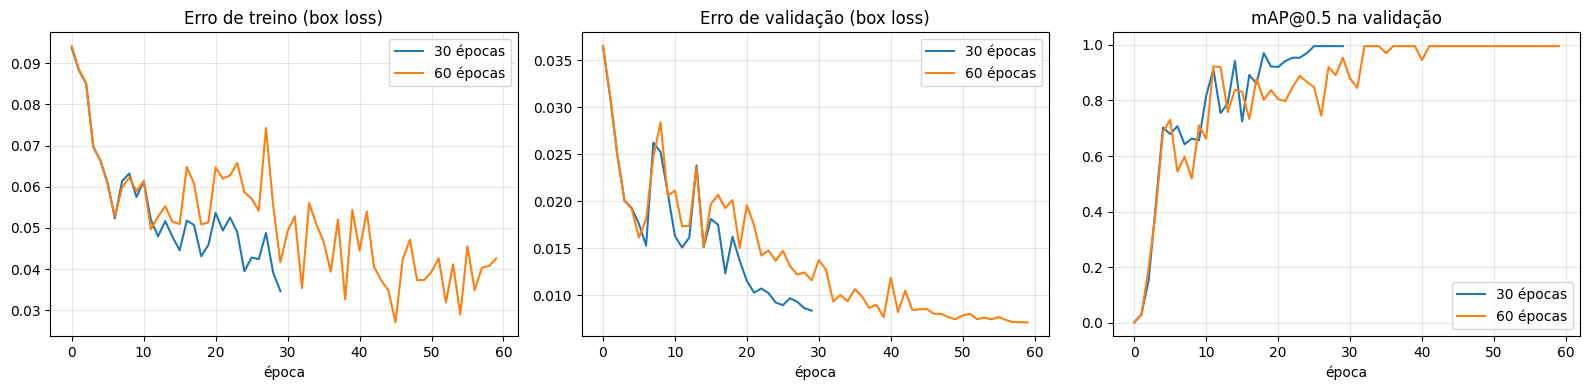

In [15]:
def ler_resultados(nome):
    df = pd.read_csv(YOLO_DIR / 'runs' / 'train' / nome / 'results.csv')
    df.columns = df.columns.str.strip()                             # o YOLOv5 grava os nomes com espaços
    return df

res = {'30 épocas': ler_resultados('exp_30ep'), '60 épocas': ler_resultados('exp_60ep')}

# Métricas da última época de cada simulação (validação)
linhas = []
for nome, df in res.items():
    u = df.iloc[-1]
    linhas.append({'Simulação': nome,
                   'Precisão': u['metrics/precision'], 'Recall': u['metrics/recall'],
                   'mAP@0.5': u['metrics/mAP_0.5'], 'mAP@0.5:0.95': u['metrics/mAP_0.5:0.95'],
                   'Loss val (box)': u['val/box_loss']})
tabela_val = pd.DataFrame(linhas).round(3)
display(tabela_val)

# Gráficos comparativos
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for nome, df in res.items():
    ax[0].plot(df['train/box_loss'], label=nome)
    ax[1].plot(df['val/box_loss'], label=nome)
    ax[2].plot(df['metrics/mAP_0.5'], label=nome)
for a, t in zip(ax, ['Erro de treino (box loss)', 'Erro de validação (box loss)', 'mAP@0.5 na validação']):
    a.set_title(t); a.set_xlabel('época'); a.legend(); a.grid(alpha=.3)
plt.tight_layout()
fig.savefig(ASSETS / 'curvas_30x60_epocas.png', dpi=90, bbox_inches='tight')   # figura para o README
plt.show()

In [16]:
# Escolha do melhor modelo pela VALIDAÇÃO (nunca pelo teste): maior mAP@0.5, desempate por mAP@0.5:0.95
ordem = tabela_val.sort_values(['mAP@0.5', 'mAP@0.5:0.95'], ascending=False, kind='stable')
melhor_nome = ordem.iloc[0]['Simulação']
EXP = {'30 épocas': ('exp_30ep', tempo_treino_30), '60 épocas': ('exp_60ep', tempo_treino_60)}
melhor_exp, melhor_tempo = EXP[melhor_nome]
print(f'Melhor modelo na validação: {melhor_nome} ({melhor_exp})')

Melhor modelo na validação: 30 épocas (exp_30ep)


### 3.2 Teste: métricas e imagens processadas

Avaliação do `best.pt` de cada simulação nas 8 imagens da pasta `test`.

In [17]:
resultados_teste = {}
for nome, exp in [('30 épocas', 'exp_30ep'), ('60 épocas', 'exp_60ep')]:
    saida = rodar('val.py', '--weights', f'runs/train/{exp}/weights/best.pt', '--data', DATA_YAML, '--task', 'test',
                  '--img', IMG, '--name', f'test_{exp}', '--exist-ok', log=f'teste_{exp}')
    linha = next(l for l in saida if l.strip().startswith('all')).split()   # linha "all": métricas das 8 imagens
    P, R, m50, m95 = map(float, linha[3:7])
    resultados_teste[nome] = {'Precisão': P, 'Recall': R, 'mAP@0.5': m50, 'mAP@0.5:0.95': m95}

display(pd.DataFrame(resultados_teste).T.round(3))

,Precisão,Recall,mAP@0.5,mAP@0.5:0.95
30 épocas,0.840,0.841,0.912,0.634
60 épocas,0.865,0.861,0.847,0.509


In [18]:
# Detecção nas imagens de teste (resultados em yolov5/runs/detect/detect_XXep)
for exp in ['exp_30ep', 'exp_60ep']:
    saida = rodar('detect.py', '--weights', f'runs/train/{exp}/weights/best.pt', '--source', LOCAL / 'images' / 'test',
                  '--img', IMG, '--conf-thres', 0.25, '--name', f'detect_{exp}', '--exist-ok', log=f'deteccao_{exp}')
    print(saida[-1])                                                # "Results saved to runs/detect/..."

def grade_deteccoes(exp, titulo, arquivo_png):
    """Mostra as 8 imagens de teste processadas pelo modelo e salva a figura em assets/."""
    fotos = sorted((YOLO_DIR / 'runs' / 'detect' / f'detect_{exp}').glob('*.jpg'))
    fig, eixos = plt.subplots(2, 4, figsize=(18, 9))
    for ax, f in zip(eixos.ravel(), fotos):
        ax.imshow(Image.open(f)); ax.set_title(f.name); ax.axis('off')
    fig.suptitle(titulo, fontsize=14)
    plt.tight_layout()
    fig.savefig(ASSETS / arquivo_png, dpi=80, bbox_inches='tight')  # print para o README
    plt.show()

# Mostra as imagens processadas pelo modelo de 60 épocas
grade_deteccoes('exp_60ep', 'Imagens de teste processadas – YOLOv5s, 60 épocas', 'deteccoes_teste_60ep.png')

Output hidden; open in https://colab.research.google.com to view.

In [19]:
# Mostra também o modelo de 30 épocas, para comparar visualmente
grade_deteccoes('exp_30ep', 'Imagens de teste processadas – YOLOv5s, 30 épocas', 'deteccoes_teste_30ep.png')

# Guarda o best.pt escolhido pela validação (usado no "Ir Além") e as curvas de treino do YOLO
shutil.copy(YOLO_DIR / 'runs' / 'train' / melhor_exp / 'weights' / 'best.pt', MODELOS / 'best.pt')
for exp in ['exp_30ep', 'exp_60ep']:
    shutil.copy(YOLO_DIR / 'runs' / 'train' / exp / 'results.png', ASSETS / f'resultados_yolo_{exp}.png')
print('best.pt do modelo escolhido salvo em models/best.pt')
if EM_COLAB:                                                        # no Colab, salva todos os resultados no Drive
    shutil.copytree(YOLO_DIR / 'runs', BASE / 'runs', dirs_exist_ok=True)
    print('Resultados salvos em', BASE / 'runs')

Output hidden; open in https://colab.research.google.com to view.

## 4. Entrega 2 – Comparação de abordagens

Comparo três abordagens sobre a **mesma base de teste**:

| Abordagem | Descrição |
|---|---|
| **A. YOLO customizado** | YOLOv5s com fine-tuning nas nossas classes (Entrega 1) |
| **B. YOLO padrão** | YOLOv5s com pesos originais do COCO, **sem treinar**. O COCO tem a classe `cow`, mas **não tem `trator`**; usei `truck` como equivalente aproximado |
| **C. CNN do zero** | Rede convolucional pequena treinada só com nossas 64 imagens, classificando a imagem inteira |

**Métrica comum:** acurácia por imagem. Nos YOLOs, a classe da detecção com maior confiança define a classe da imagem; sem detecção conta como erro. Também meço o **tempo médio de inferência** por imagem.

In [20]:
print('Dispositivo de inferência:', DISPOSITIVO)

pasta_teste = LOCAL / 'images' / 'test'
arquivos_teste = sorted(pasta_teste.glob('*.jpg'))

def avaliar_yolo(modelo, mapa=None):
    modelo.conf = 0.25
    modelo(str(arquivos_teste[0]))                                  # aquecimento (não entra na medida)
    acertos, tempos, previsoes = 0, [], []
    for f in arquivos_teste:
        verdade = f.name.split('_')[0]                              # a classe verdadeira está no nome do arquivo
        t0 = time.perf_counter()
        r = modelo(str(f), size=IMG)
        tempos.append(time.perf_counter() - t0)
        df = r.pandas().xyxy[0]
        if mapa is not None:                                        # traduz classes do COCO para as nossas
            df = df[df['name'].isin(mapa)].copy()
            df['name'] = df['name'].map(mapa)
        pred = df.sort_values('confidence', ascending=False)['name'].iloc[0] if len(df) else 'nenhum'
        previsoes.append((f.name, verdade, pred))
        acertos += (pred == verdade)
    return acertos / len(arquivos_teste), np.mean(tempos) * 1000, previsoes

# A. YOLO customizado: modelo escolhido pela validação (seção 3.1)
yolo_custom = torch.hub.load(str(YOLO_DIR), 'custom', path=str(YOLO_DIR / 'runs' / 'train' / melhor_exp / 'weights' / 'best.pt'), source='local')
acc_A, ms_A, prev_A = avaliar_yolo(yolo_custom)

# B. YOLO padrão (pesos originais do COCO): cow -> vaca, truck -> trator (aproximação)
yolo_padrao = torch.hub.load(str(YOLO_DIR), 'custom', path=str(YOLO_DIR / 'yolov5s.pt'), source='local')
acc_B, ms_B, prev_B = avaliar_yolo(yolo_padrao, mapa={'cow': 'vaca', 'truck': 'trator'})

print(f'A) YOLO customizado: acurácia {acc_A:.0%} | {ms_A:.1f} ms/imagem')
print(f'B) YOLO padrão:      acurácia {acc_B:.0%} | {ms_B:.1f} ms/imagem')
print('\nPrevisões do YOLO padrão (arquivo, verdade, previsto):')
for p in prev_B: print(p)

Dispositivo de inferência: GPU Tesla T4
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
Adding AutoShape... 
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs
Adding AutoShape... 
A) YOLO customizado: acurácia 88% | 23.1 ms/imagem
B) YOLO padrão:      acurácia 38% | 16.9 ms/imagem

Previsões do YOLO padrão (arquivo, verdade, previsto):
('trator_37.jpg', 'trator', 'nenhum')
('trator_38.jpg', 'trator', 'nenhum')
('trator_39.jpg', 'trator', 'nenhum')
('trator_40.jpg', 'trator', 'trator')
('vaca_37.jpg', 'vaca', 'vaca')
('vaca_38.jpg', 'vaca', 'nenhum')
('vaca_39.jpg', 'vaca', 'nenhum')
('vaca_40.jpg', 'vaca', 'vaca')


### 4.1 CNN treinada do zero

Rede pequena (3 blocos convolucionais) com *data augmentation* (espelhamento, rotação e zoom), porque 64 imagens de treino é muito pouco. Ela só diz **qual classe** a imagem tem; não localiza o objeto.

In [21]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

tf.keras.utils.set_random_seed(42)                                  # pesos iniciais e augmentation reprodutíveis
LADO = 128

def carregar(split):
    X, y = [], []
    for f in sorted((LOCAL / 'images' / split).glob('*.jpg')):
        X.append(np.array(Image.open(f).convert('RGB').resize((LADO, LADO))))
        y.append(1 if f.name.startswith('vaca') else 0)             # 0 = trator, 1 = vaca
    return np.array(X, dtype='float32'), np.array(y)

Xtr, ytr = carregar('train'); Xva, yva = carregar('val'); Xte, yte = carregar('test')
print(Xtr.shape, Xva.shape, Xte.shape)

cnn = models.Sequential([
    layers.Input((LADO, LADO, 3)),
    layers.Rescaling(1/255),                                        # normaliza pixels para 0-1
    layers.RandomFlip('horizontal'), layers.RandomRotation(0.1), layers.RandomZoom(0.15),
    layers.Conv2D(16, 3, activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(32, 3, activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'), layers.MaxPooling2D(),
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='sigmoid'),                          # probabilidade de ser vaca
])
cnn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
cnn.summary()

(64, 128, 128, 3) (8, 128, 128, 3) (8, 128, 128, 3)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,697 (100.38 KB)

 Trainable params: 25,697 (100.38 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/60
4/4 - 6s - 1s/step - accuracy: 0.4844 - loss: 0.7011 - val_accuracy: 0.5000 - val_loss: 0.6959
Epoch 2/60
4/4 - 0s - 34ms/step - accuracy: 0.5781 - loss: 0.6859 - val_accuracy: 0.5000 - val_loss: 0.6945
Epoch 3/60
4/4 - 0s - 36ms/step - accuracy: 0.5000 - loss: 0.6857 - val_accuracy: 0.5000 - val_loss: 0.6946
Epoch 4/60
4/4 - 0s - 54ms/step - accuracy: 0.4531 - loss: 0.6870 - val_accuracy: 0.5000 - val_loss: 0.6944
Epoch 5/60
4/4 - 0s - 38ms/step - accuracy: 0.5156 - loss: 0.6870 - val_accuracy: 0.5000 - val_loss: 0.6930
Epoch 6/60
4/4 - 0s - 33ms/step - accuracy: 0.5781 - loss: 0.6857 - val_accuracy: 0.5000 - val_loss: 0.6930
Epoch 7/60
4/4 - 0s - 34ms/step - accuracy: 0.5781 - loss: 0.6880 - val_accuracy: 0.5000 - val_loss: 0.6946
Epoch 8/60
4/4 - 0s - 32ms/step - accuracy: 0.5625 - loss: 0.6804 - val_accuracy: 0.5000 - val_loss: 0.6927
Epoch 9/60
4/4 - 0s - 33ms/step - accuracy: 0.5156 - loss: 0.6844 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 10/60
4/4 - 0s - 35ms/st

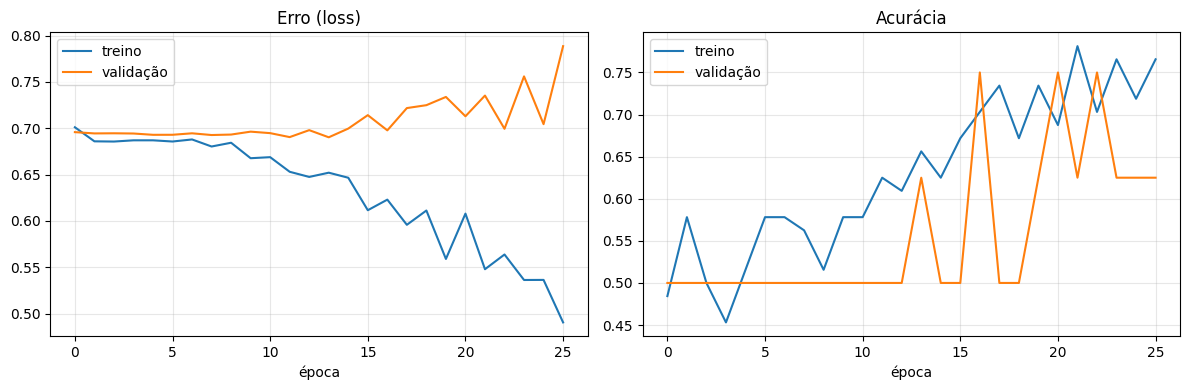

In [22]:
parar = callbacks.EarlyStopping(patience=12, restore_best_weights=True, monitor='val_loss')

t0 = time.time()
hist = cnn.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=60, batch_size=16, callbacks=[parar], verbose=2)
tempo_treino_cnn = time.time() - t0
print(f'Tempo de treino da CNN: {tempo_treino_cnn:.1f} s')

# Curvas de aprendizado
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist.history['loss'], label='treino'); ax[0].plot(hist.history['val_loss'], label='validação'); ax[0].set_title('Erro (loss)')
ax[1].plot(hist.history['accuracy'], label='treino'); ax[1].plot(hist.history['val_accuracy'], label='validação'); ax[1].set_title('Acurácia')
for a in ax: a.legend(); a.grid(alpha=.3); a.set_xlabel('época')
plt.tight_layout(); plt.show()

C) CNN do zero: acurácia 62% | 74.9 ms/imagem


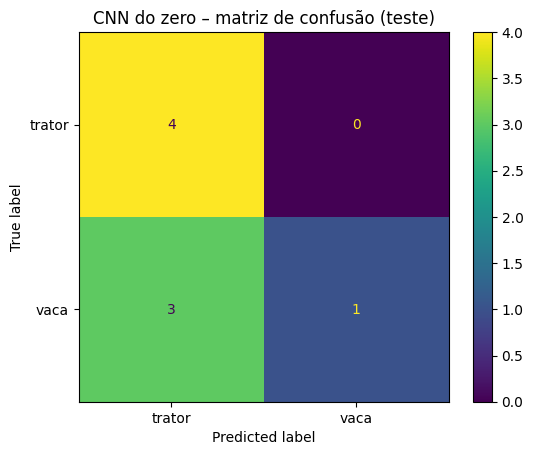

In [23]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

pred_cnn = (cnn.predict(Xte, verbose=0).ravel() > 0.5).astype(int)
acc_C = (pred_cnn == yte).mean()

# Tempo de inferência por imagem (uma a uma, igual aos YOLOs)
cnn.predict(Xte[:1], verbose=0)                                     # aquecimento
tempos = []
for i in range(len(Xte)):
    t0 = time.perf_counter(); cnn.predict(Xte[i:i+1], verbose=0); tempos.append(time.perf_counter() - t0)
ms_C = np.mean(tempos) * 1000

print(f'C) CNN do zero: acurácia {acc_C:.0%} | {ms_C:.1f} ms/imagem')
ConfusionMatrixDisplay(confusion_matrix(yte, pred_cnn, labels=[0, 1]), display_labels=['trator', 'vaca']).plot()
plt.title('CNN do zero – matriz de confusão (teste)'); plt.show()

### 4.2 Comparação final

,Abordagem,Acurácia no teste,Tempo de treino (min),Inferência (ms/imagem),Localiza o objeto?
0,A. YOLO customizado (30 épocas),0.875,1.506,23.053,Sim
1,B. YOLO padrão (COCO),0.375,0.000,16.850,Sim
2,C. CNN do zero,0.625,0.162,74.908,Não


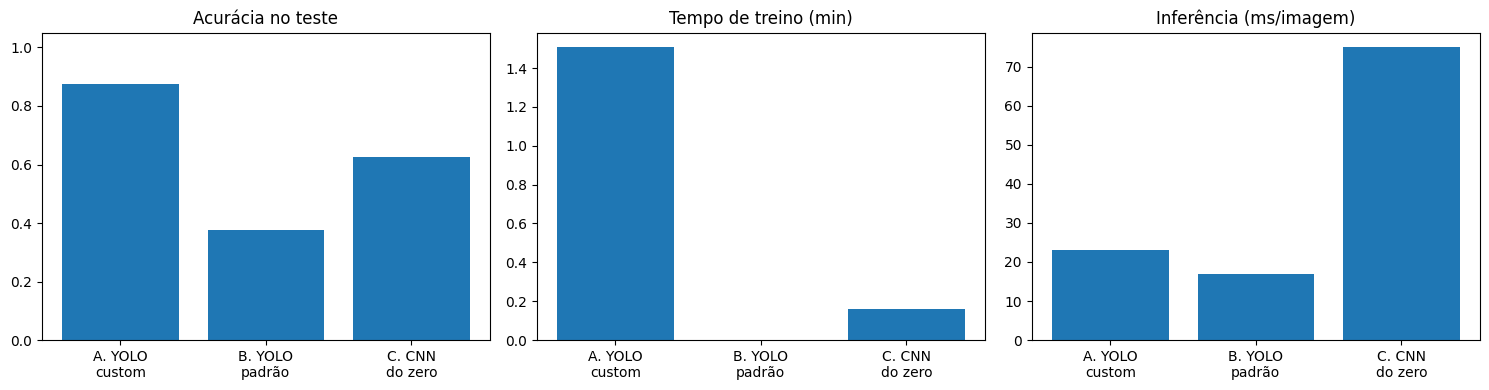

In [24]:
comparacao = pd.DataFrame({
    'Abordagem': [f'A. YOLO customizado ({melhor_nome})', 'B. YOLO padrão (COCO)', 'C. CNN do zero'],
    'Acurácia no teste': [acc_A, acc_B, acc_C],
    'Tempo de treino (min)': [melhor_tempo / 60, 0.0, tempo_treino_cnn / 60],
    'Inferência (ms/imagem)': [ms_A, ms_B, ms_C],
    'Localiza o objeto?': ['Sim', 'Sim', 'Não'],
}).round(3)
display(comparacao)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
nomes = ['A. YOLO\ncustom', 'B. YOLO\npadrão', 'C. CNN\ndo zero']
ax[0].bar(nomes, comparacao['Acurácia no teste']); ax[0].set_title('Acurácia no teste'); ax[0].set_ylim(0, 1.05)
ax[1].bar(nomes, comparacao['Tempo de treino (min)']); ax[1].set_title('Tempo de treino (min)')
ax[2].bar(nomes, comparacao['Inferência (ms/imagem)']); ax[2].set_title('Inferência (ms/imagem)')
plt.tight_layout(); plt.show()

In [25]:
# Comparação crítica gerada com os números desta execução
from IPython.display import Markdown, display

tA = resultados_teste[melhor_nome]
display(Markdown(f"""
### 4.3 Comparação crítica (números desta execução; inferência em **{DISPOSITIVO}**)

| Critério | A. YOLO customizado ({melhor_nome}) | B. YOLO padrão (COCO) | C. CNN do zero |
|---|---|---|---|
| **Facilidade de uso/integração** | Média: exige rotular caixas, treinar e gerenciar o repositório YOLOv5, mas entrega um `best.pt` pronto para webcam/ESP32-CAM. | Alta: zero treino, poucas linhas de código. | Média: código curto em Keras, mas é preciso projetar a arquitetura e ajustar hiperparâmetros. |
| **Precisão** | Acurácia por imagem **{acc_A:.0%}**; mAP@0.5 no teste **{tA['mAP@0.5']:.3f}** | Acurácia por imagem **{acc_B:.0%}** (`trator` não existe no COCO; `truck` é aproximação) | Acurácia por imagem **{acc_C:.0%}** (só classifica, não localiza) |
| **Tempo de treino** | {melhor_tempo/60:.1f} min | Nenhum (pesos prontos) | {tempo_treino_cnn:.0f} s |
| **Tempo de inferência** | {ms_A:.1f} ms/imagem | {ms_B:.1f} ms/imagem | {ms_C:.1f} ms/imagem |
"""))

ranking = sorted([('A. YOLO customizado', acc_A), ('B. YOLO padrão', acc_B), ('C. CNN do zero', acc_C)], key=lambda x: -x[1])
rapido = min([('A', ms_A), ('B', ms_B), ('C', ms_C)], key=lambda x: x[1])[0]
display(Markdown(f"""
**Leitura dos resultados**
- Maior acurácia por imagem no teste: **{ranking[0][0]}** ({ranking[0][1]:.0%}); menor: **{ranking[-1][0]}** ({ranking[-1][1]:.0%}).
- Menor tempo de inferência: abordagem **{rapido}**. As medidas não são perfeitamente equivalentes: no YOLO o tempo inclui pré e pós-processamento, e na CNN o `predict` do Keras tem overhead próprio por chamada.
- O YOLO padrão não conhece `trator`: o desempenho nessa classe depende de o modelo confundir o trator com `truck`, o que mostra por que o *fine-tuning* é necessário para objetos fora do COCO.
- A CNN só diz **qual** classe a imagem tem; o YOLO também diz **onde** o objeto está e lida com cenas de vários objetos.
- Com apenas 8 imagens de teste, cada erro pesa 12,5 pontos percentuais: os números são indicativos, não conclusivos.
"""))


### 4.3 Comparação crítica (números desta execução; inferência em **GPU Tesla T4**)

| Critério | A. YOLO customizado (30 épocas) | B. YOLO padrão (COCO) | C. CNN do zero |
|---|---|---|---|
| **Facilidade de uso/integração** | Média: exige rotular caixas, treinar e gerenciar o repositório YOLOv5, mas entrega um `best.pt` pronto para webcam/ESP32-CAM. | Alta: zero treino, poucas linhas de código. | Média: código curto em Keras, mas é preciso projetar a arquitetura e ajustar hiperparâmetros. |
| **Precisão** | Acurácia por imagem **88%**; mAP@0.5 no teste **0.912** | Acurácia por imagem **38%** (`trator` não existe no COCO; `truck` é aproximação) | Acurácia por imagem **62%** (só classifica, não localiza) |
| **Tempo de treino** | 1.5 min | Nenhum (pesos prontos) | 10 s |
| **Tempo de inferência** | 23.1 ms/imagem | 16.9 ms/imagem | 74.9 ms/imagem |



**Leitura dos resultados**
- Maior acurácia por imagem no teste: **A. YOLO customizado** (88%); menor: **B. YOLO padrão** (38%).
- Menor tempo de inferência: abordagem **B**. As medidas não são perfeitamente equivalentes: no YOLO o tempo inclui pré e pós-processamento, e na CNN o `predict` do Keras tem overhead próprio por chamada.
- O YOLO padrão não conhece `trator`: o desempenho nessa classe depende de o modelo confundir o trator com `truck`, o que mostra por que o *fine-tuning* é necessário para objetos fora do COCO.
- A CNN só diz **qual** classe a imagem tem; o YOLO também diz **onde** o objeto está e lida com cenas de vários objetos.
- Com apenas 8 imagens de teste, cada erro pesa 12,5 pontos percentuais: os números são indicativos, não conclusivos.


## 5. Conclusões

In [26]:
# Conclusões sobre 30 x 60 épocas, geradas a partir de results.csv e das métricas de teste
m30, m60 = res['30 épocas'], res['60 épocas']
v30, v60 = tabela_val.set_index('Simulação').loc['30 épocas'], tabela_val.set_index('Simulação').loc['60 épocas']
t30, t60 = resultados_teste['30 épocas'], resultados_teste['60 épocas']

def sinal_overfit(df):
    """Compara o menor erro de validação com o erro final: alta relevante indica overfitting."""
    menor, final = df['val/box_loss'].min(), df['val/box_loss'].iloc[-1]
    ep = int(df['val/box_loss'].idxmin()) + 1
    return (final > menor * 1.15), ep, menor, final

o30, o60 = sinal_overfit(m30), sinal_overfit(m60)
ganho_val = v60['mAP@0.5'] - v30['mAP@0.5']
ganho_teste = t60['mAP@0.5'] - t30['mAP@0.5']

display(Markdown(f"""
### Efeito do número de épocas (30 × 60)
- **Validação:** mAP@0.5 foi de **{v30['mAP@0.5']:.3f}** (30 ép.) para **{v60['mAP@0.5']:.3f}** (60 ép.), variação de **{ganho_val:+.3f}**; precisão {v30['Precisão']:.3f} → {v60['Precisão']:.3f} e recall {v30['Recall']:.3f} → {v60['Recall']:.3f}.
- **Teste:** mAP@0.5 de **{t30['mAP@0.5']:.3f}** → **{t60['mAP@0.5']:.3f}** ({ganho_teste:+.3f}).
- **Overfitting:** com 30 épocas, o menor erro de validação ocorreu na época {o30[1]} ({o30[2]:.4f}) e terminou em {o30[3]:.4f} — {'há sinal de overfitting' if o30[0] else 'sem sinal relevante de overfitting'}. Com 60 épocas, o menor foi na época {o60[1]} ({o60[2]:.4f}) e terminou em {o60[3]:.4f} — {'há sinal de overfitting' if o60[0] else 'sem sinal relevante de overfitting'}.
- **Custo:** {tempo_treino_30/60:.1f} min contra {tempo_treino_60/60:.1f} min ({tempo_treino_60/tempo_treino_30:.1f}x mais tempo). {'O ganho de mAP justifica o custo extra.' if ganho_val > 0.02 else 'O ganho de mAP é pequeno diante do tempo extra, então o custo adicional compensa pouco.'}
- **Modelo escolhido pela validação:** {melhor_nome}.
"""))


### Efeito do número de épocas (30 × 60)
- **Validação:** mAP@0.5 foi de **0.995** (30 ép.) para **0.995** (60 ép.), variação de **+0.000**; precisão 0.970 → 0.984 e recall 1.000 → 1.000.
- **Teste:** mAP@0.5 de **0.912** → **0.847** (-0.065).
- **Overfitting:** com 30 épocas, o menor erro de validação ocorreu na época 30 (0.0084) e terminou em 0.0084 — sem sinal relevante de overfitting. Com 60 épocas, o menor foi na época 60 (0.0071) e terminou em 0.0071 — sem sinal relevante de overfitting.
- **Custo:** 1.5 min contra 2.3 min (1.5x mais tempo). O ganho de mAP é pequeno diante do tempo extra, então o custo adicional compensa pouco.
- **Modelo escolhido pela validação:** 30 épocas.
